# 1 TeV 固定靶 pp 碰撞：质子能损分布

每个事件都是一个动能 $T_0=1000$ GeV 的质子与静止质子的**独立非弹性碰撞**，不是同一质子的连续传播。使用 PYTHIA 8.318、`SoftQCD:inelastic` 和默认衰变，固定随机种子 12345；无气体密度或传播时间。

定义领先质子为末态中实验室能量最高的质子，包括靶反冲候选，无法把它严格识别为原入射质子。对含质子的事件定义
$$\kappa_{\rm lead}=1-T_{\rm lead}/T_0,\qquad \Delta T=T_0-T_{\rm lead}.$$
无末态质子的事件没有这个能损变量，单独报告其比例，不将它们当作 $\kappa=1$。图中的 PDF 是**条件于存在末态质子**的概率密度，而非反应截面。

先在 `external/` 运行 `make pp_fixed_target` 和 `./pp_fixed_target > pp_fixed_target.log 2>&1`，再执行本 notebook。

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

T_beam = 1000.0  # GeV, incident kinetic energy
N_events_expected = 10000
file = Path('pp_fixed_target_events.csv')
if not file.exists():
    file = Path('external/pp_fixed_target_events.csv')
if not file.exists():
    file = Path('../external/pp_fixed_target_events.csv')


CSV 每行一个事件，能量和动量单位分别为 GeV 和 GeV/c（自然单位 $c=1$）。`T_sum_protons_GeV` 是所有末态质子的动能之和；`dE_GeV` 和 `dp_GeV` 用所有末态粒子计算能量和总动量守恒残差。没有质子的事件中，`T_leading_GeV`、`kappa_leading` 为 NaN。

In [17]:
# genfromtxt reads the named CSV columns and preserves NaN for undefined energies.
data = np.genfromtxt(file, delimiter=',', names=True)

T_beam = data['T_beam_GeV']
p1 = data['nucleon1_pdg']
T_p1 = data['T_nucleon1_GeV']
p2 = data['nucleon2_pdg']
T_p2 = data['T_nucleon2_GeV']
T_leading = T_p1 + T_p2

print(np.max(T_p1), np.min(T_p1))




999.6671743222337 1.704770718952795


## 能损概率密度和累积分布

等宽 bin 的概率密度为 $n_i/(N_p\Delta\kappa)$，其中 $N_p$ 是含末态质子的事件数。因此 PDF 对 $\kappa$ 的积分为 1。经验累积分布是在每个能损阈值以下的事件比例。$\kappa=0.5$ 竖线只表示原程序的固定能损假设，不是连续概率密度。

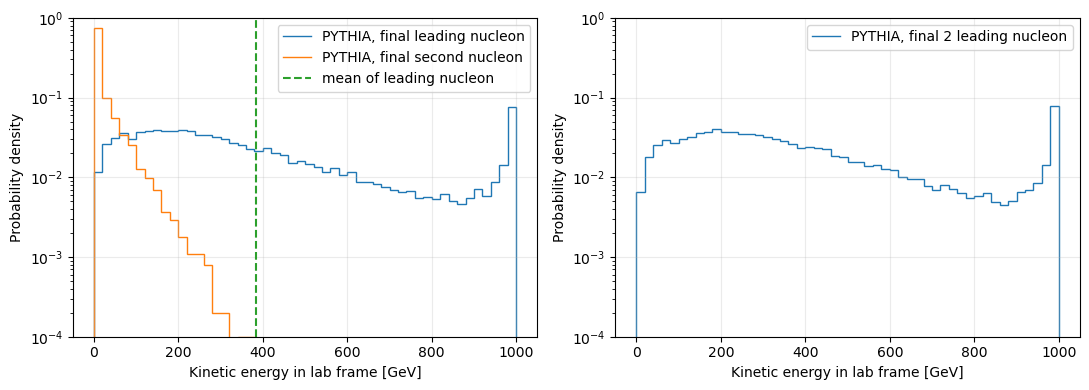

In [37]:
bins = np.linspace(0.0, 1000.0, 51)

counts_p1, edges_p1 = np.histogram(T_p1, bins=bins)
counts_p2, edges_p2 = np.histogram(T_p2, bins=bins)
counts_lead, edges_lead = np.histogram(T_leading, bins=bins)

bin_width = edges[1:] - edges[:-1]
centers = 0.5 * (edges[1:] + edges[:-1])

mean_p1 = np.sum(counts_p1*centers)/10000


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].stairs( counts_p1/1e4, edges_p1, label='PYTHIA, final leading nucleon')
axes[0].stairs( counts_p2/1e4, edges_p2, label='PYTHIA, final second nucleon')
axes[0].plot(mean_p1*np.ones(100), np.logspace(-4,0,100), label="mean of leading nucleon", linestyle="--")
axes[0].set_xlabel(r'Kinetic energy in lab frame [GeV]')
axes[0].set_ylabel('Probability density')

axes[1].stairs( counts_lead/1e4, edges_lead, label='PYTHIA, final 2 leading nucleon')
axes[1].set_xlabel(r'Kinetic energy in lab frame [GeV]')
axes[1].set_ylabel('Probability density')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
    ax.set_yscale("log")
    # ax.set_xscale("log")
    ax.set_ylim(1e-4,1e0)
fig.tight_layout()
fig.savefig(file.parent / 'pp_fixed_target_loss_distribution.png', dpi=180)
plt.show()

In [35]:
np.sum(mean_p1)

np.float64(384.08)

这里的能损是从**领先质子分支**转移出去的动能，并不全部变成 pion 或光子；其他质子、中子等也会携带能量。此结果不能直接替代包含所有核子再生的输运计算，也不是随传播时间变化的能谱。